
QUESTION 4 – LDA TOPIC MODELLING

Number of articles: 5
Missing cleaned articles: 0

Document-Term Matrix Shape: (5, 1000)

TOP WORDS PER TOPIC

Topic 1:
alpha, cronbach, instrument, science, reliability, values, items, education, authors, scales

Topic 2:
research, data, development, triangulation, design, study, developmental, process, instructional, qualitative

Topic 3:
research, qualitative, methods, mixed, researchers, researcher, quantitative, data, reflexivity, social

DOCUMENT-TOPIC DISTRIBUTION
       Article  Topic 1  Topic 2  Topic 3
research_1.txt 0.000152 0.000158 0.999690
research_2.txt 0.000476 0.000524 0.998999
research_3.txt 0.000240 0.999523 0.000237
research_4.txt 0.999704 0.000149 0.000147
research_5.txt 0.000219 0.999545 0.000236

OVERALL TOPIC DISTRIBUTION
  Topic  Average Distribution
Topic 1              0.200158
Topic 2              0.399980
Topic 3              0.399862


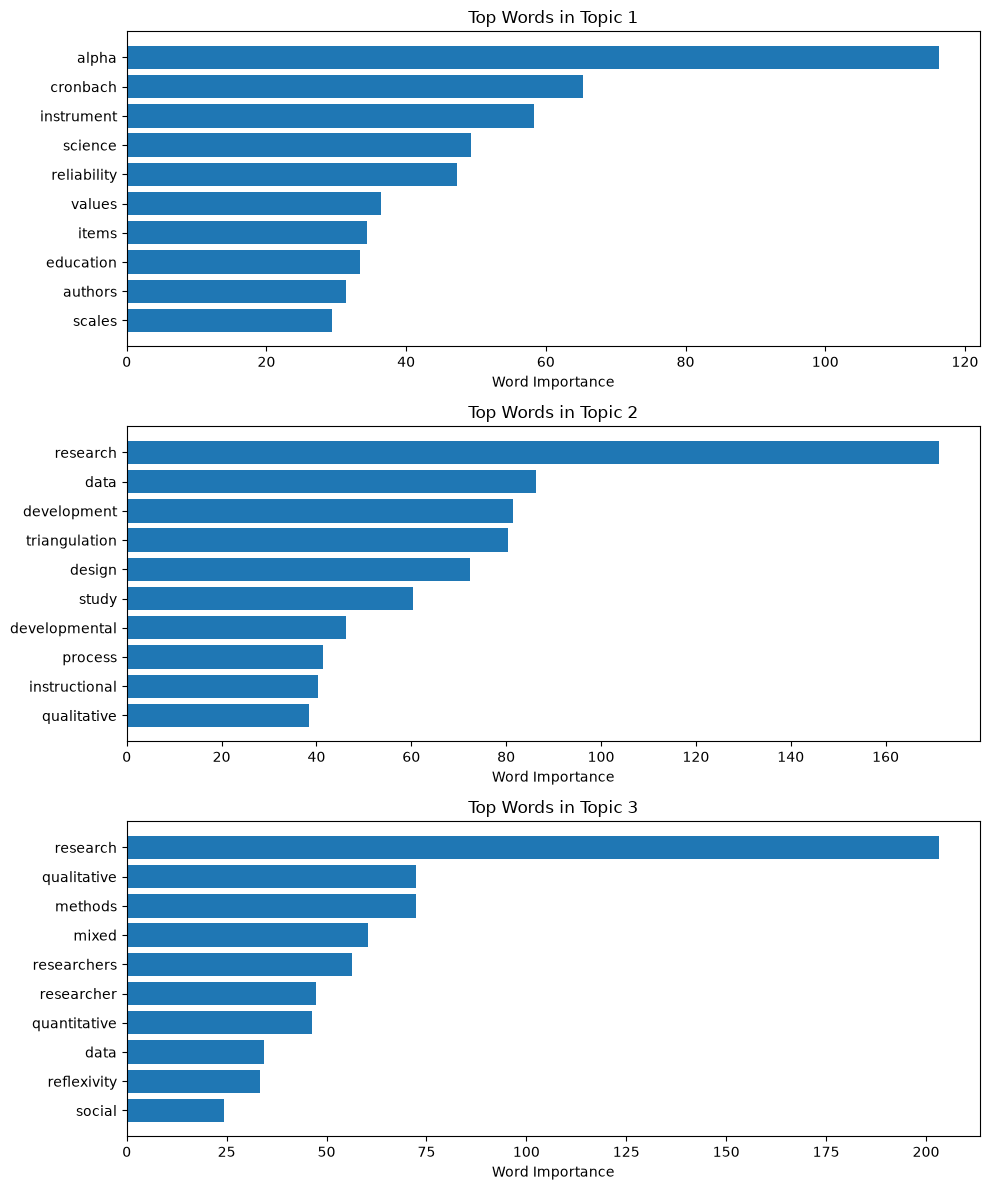

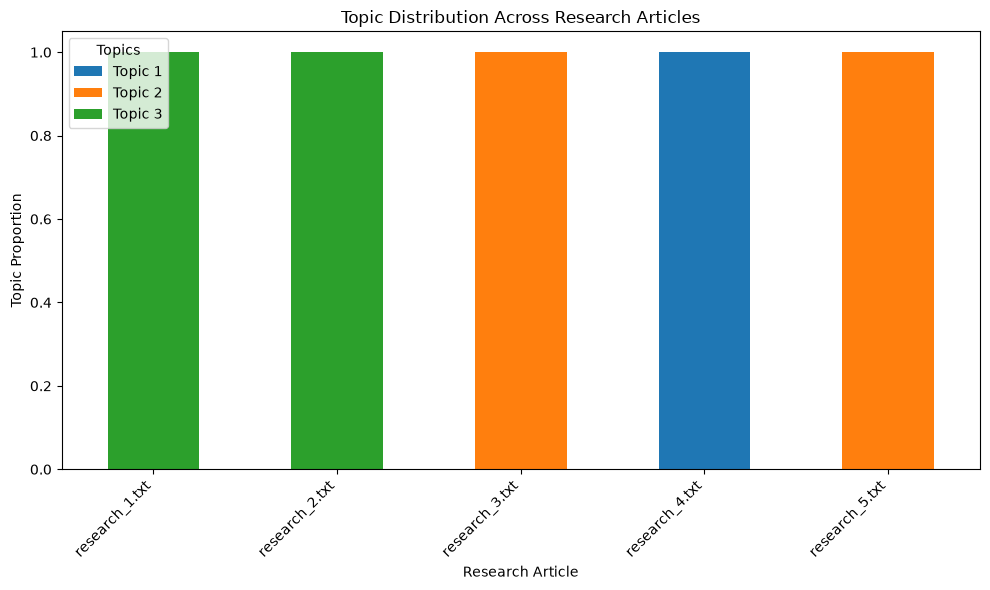

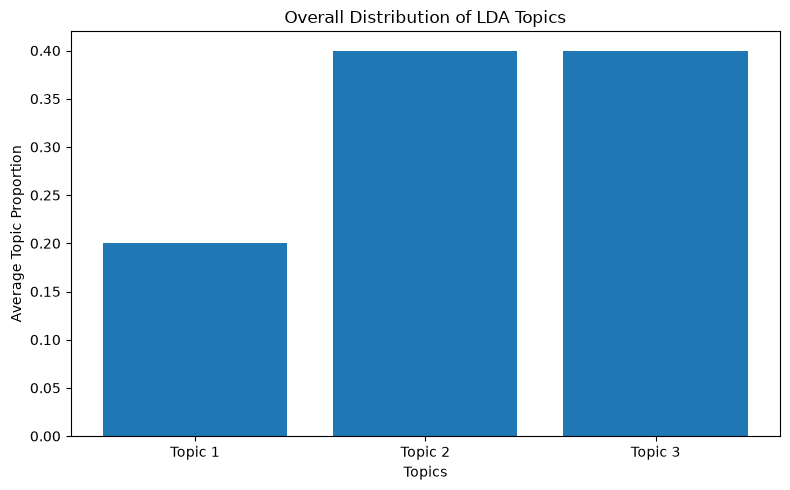


Interactive LDA visualisation saved as:
lda_intertopic_map.html


In [1]:
#4.1

import zipfile
import re
import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import pyLDAvis
import pyLDAvis.lda_model


# Load the research articles
articles = []

with zipfile.ZipFile("C:\\Users\\kgour\\OneDrive\\Documents\\School\\ITNP\\Research-Document-Mining\\datasets\\research_corpus.zip", "r") as zip_file:

    for filename in zip_file.namelist():

        if filename.lower().endswith(".txt"):

            content = zip_file.read(filename).decode(
                "utf-8", errors="replace"
            )

            articles.append({
                "Article": os.path.basename(filename),
                "Content": content
            })

df = pd.DataFrame(articles)

print("\nQUESTION 4 – LDA TOPIC MODELLING")
print("\nNumber of articles:", len(df))



# Preprocess the articles
def clean_text(text):

    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"doi:\s*\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["Cleaned_Content"] = df["Content"].apply(clean_text)

print("Missing cleaned articles:", df["Cleaned_Content"].isna().sum())


# Create the document-term matrix
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=1,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b"
)

dtm = vectorizer.fit_transform(df["Cleaned_Content"])

print("\nDocument-Term Matrix Shape:", dtm.shape)


# Train the LDA model
n_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=20,
    learning_method="batch"
)

lda_model.fit(dtm)


# Display the top words
feature_names = vectorizer.get_feature_names_out()
n_top_words = 10

print("\nTOP WORDS PER TOPIC")

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-n_top_words:][::-1]

    top_words = [
        feature_names[index] for index in top_indices
    ]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))


# Display document-topic distribution
document_topic_distribution = lda_model.transform(dtm)

topic_columns = [
    f"Topic {i + 1}" for i in range(n_topics)
]

distribution_df = pd.DataFrame(
    document_topic_distribution,
    columns=topic_columns
)

distribution_df.insert(0, "Article", df["Article"])

print("\nDOCUMENT-TOPIC DISTRIBUTION")
print(distribution_df.to_string(index=False))


overall_distribution = document_topic_distribution.mean(axis=0)

overall_topic_df = pd.DataFrame({
    "Topic": topic_columns,
    "Average Distribution": overall_distribution
})

print("\nOVERALL TOPIC DISTRIBUTION")
print(overall_topic_df.to_string(index=False))


# Visualisation 1
fig, axes = plt.subplots(
    n_topics, 1,
    figsize=(10, 12)
)

for topic_index, topic in enumerate(lda_model.components_):

    top_indices = topic.argsort()[-n_top_words:][::-1]

    words = feature_names[top_indices]
    weights = topic[top_indices]

    axes[topic_index].barh(words[::-1], weights[::-1])
    axes[topic_index].set_title(
        f"Top Words in Topic {topic_index + 1}"
    )
    axes[topic_index].set_xlabel("Word Importance")

plt.tight_layout()
plt.show()


# Visualisation 2
plot_df = distribution_df.set_index("Article")

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Topic Distribution Across Research Articles")
plt.xlabel("Research Article")
plt.ylabel("Topic Proportion")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Topics")
plt.tight_layout()
plt.show()


# Visualisation 3
plt.figure(figsize=(8, 5))

plt.bar(
    overall_topic_df["Topic"],
    overall_topic_df["Average Distribution"]
)

plt.title("Overall Distribution of LDA Topics")
plt.xlabel("Topics")
plt.ylabel("Average Topic Proportion")
plt.tight_layout()
plt.show()


#4.2

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa"
)

pyLDAvis.save_html(
    vis,
    "lda_intertopic_map.html"
)

print("\nInteractive LDA visualisation saved as:")
print("lda_intertopic_map.html")

